# 04 - Fault diagnosis: how well can the faults really be told apart?

Notebooks 02 and 03 described the faults. This notebook asks the data-science question underneath the
digital twin: **given a few seconds of sensor data, can a model say whether the system is healthy,
and if not, which component is failing and how badly?** And, as important, **how much of any good
score is real?**

Unit of analysis: 1 s windows (60 per recording, 2 820 in total), labelled with the recording's
condition (healthy, F1-F5).

**Why the validation design matters more than the model here**

* Windows from one 60 s recording are near copies. A shuffled split puts copies of the test window
  in the training set, so it measures memory.
* Every condition was recorded in its own block of the day (notebook 01), so anything that drifts
  with time can stand in for the label.
* In service the hard and valuable case is a fault that is still **mild**, while the faults a model
  could learn from are the obvious ones.

So every method is scored three ways: shuffled (for contrast), leave-one-recording-out (the setting
itself is unseen), and "incipient" (train on clear faults at >= 40 % travel plus three healthy runs,
test on the mild settings and the other three healthy runs).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import confusion_matrix
from scipy.stats import spearmanr

from fueltwin import baseline, config, diagnosis as dg, features, hydraulics as hy, plotting as pl

pl.use_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 170)
w = features.load_windows(1.0)
y = w["condition"]
LABELS = dg.LABELS

## 1. The shortcut test: what can the clock alone do?

Before trusting any sensor model, the same classifier is given a single feature that contains no
physics at all: **the time of day the window was recorded**. A second probe uses only P1, the
pressure that tracks the tank level.

In [2]:
probe = []
for fs in ["clock only", "P1 only"]:
    for split in ["random", "loro", "incipient"]:
        p = dg.run_experiment(w, fs, "random forest", split)
        probe.append({"features": fs, "split": split, **dg.score(y, p, w["run_id"])})
probe = pd.DataFrame(probe)
probe

,features,split,n_windows,accuracy,balanced_accuracy,macro_f1,recordings_correct
0,clock only,random,2820,1.000,1.000,1.000,47/47
1,clock only,loro,2820,0.960,0.961,0.958,45/47
2,clock only,incipient,960,0.625,0.611,0.603,10/16
3,P1 only,random,2820,0.588,0.580,0.581,35/47
4,P1 only,loro,2820,0.283,0.280,0.274,13/47
5,P1 only,incipient,960,0.208,0.185,0.145,3/16


**The time of day alone identifies the fault in 96 % of windows when each recording is held out**,
and it still reaches a macro F1 of 0.60 when trained on severe faults and tested on mild ones. No
sensor model below beats it on any split. The reason is the recording schedule: neighbouring
settings of each fault were recorded minutes apart, so the nearest training windows in time almost
always carry the right label. This does not make the sensor models useless, but it means that on this
dataset **a classifier's score is not by itself evidence of diagnosis**, whatever the split. Evidence
has to come from methods that cannot use time at all: the physics rules, which have no clock input
and are calibrated without any data from the fault being scored.

## 2. Methods compared

| Family | Method | Uses fault labels to train? |
|---|---|---|
| Lecture | Diagnostic tree (Diagnostic Trees p. 9) | no (hand-written rules) |
| Physics | Structured residual rules (`hydraulics.isolate`), laws fitted without the scored fault | only to pick calibration windows |
| Data-driven, transparent | Signature direction: nearest mean fault direction (cosine) | yes |
| Machine learning | Logistic regression, random forest, gradient boosting | yes |

ML feature sets: **raw** (P1-P5, Q window means), **raw+derived** (adds section pressure drops and
within-window ripple sd), **physics** (the four residuals, with laws refitted inside every training
fold).

In [3]:
results, preds = [], {}
for split in ["random", "loro", "incipient"]:
    for fs in ["raw", "raw+derived", "physics"]:
        for mn in ["logistic regression", "random forest", "gradient boosting"]:
            p = dg.run_experiment(w, fs, mn, split)
            preds[(split, fs, mn)] = p
            results.append({"split": split, "family": "machine learning", "method": f"{mn} | {fs}",
                            **dg.score(y, p, w["run_id"])})
    for fs, cols in [("raw", dg.RAW), ("raw+derived", dg.RAW_DERIVED[:10])]:
        p = dg.run_direction(w, cols, split)
        preds[(split, "direction", fs)] = p
        results.append({"split": split, "family": "signature direction", "method": f"direction | {fs}",
                        **dg.score(y, p, w["run_id"])})
print("done")

done


The two methods that need no training split are scored once on all windows and then on the
incipient test windows:

In [4]:
R, _ = hy.lofo_residuals(w)
E = R[[c for c in R if c.startswith("e_")]].rename(columns=lambda c: c.replace("e_", "r_"))
phys_pred = hy.isolate(E)
base = baseline.HealthyBaseline.fit(w, ["P1", "P2", "P3", "P4", "P5", "Q"])
tree_pred = dg.expert_tree(w, base.mean, base.sd_total)
_, inc_test = next(dg.split_incipient(w))
for name, p in [("physics residual rules (leave-one-fault-out)", phys_pred), ("expert diagnostic tree", tree_pred)]:
    fam = "physics" if "physics" in name else "expert rules"
    for split, idx in [("loro", w.index), ("incipient", inc_test)]:
        results.append({"split": split, "family": fam, "method": name,
                        **dg.score(y.loc[idx], p.loc[idx], w.loc[idx, "run_id"])})
res = pd.DataFrame(results)
res.to_csv(config.TABLE_DIR / "04_diagnosis_results.csv", index=False)
res.pivot_table(index=["family", "method"], columns="split", values="macro_f1").round(3).sort_values("loro", ascending=False)

D:\files\fuel-system-digital-twin\.venv\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
D:\files\fuel-system-digital-twin\.venv\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


split                                                             incipient   loro  random
family              method                                                                
machine learning    gradient boosting | physics                       0.547  0.921   0.998
                    logistic regression | raw+derived                 0.339  0.919   0.987
                    gradient boosting | raw+derived                   0.465  0.918   1.000
                    random forest | physics                           0.141  0.912   1.000
                    random forest | raw+derived                       0.151  0.896   1.000
physics             physics residual rules (leave-one-fault-out)      0.580  0.880     NaN
machine learning    logistic regression | raw                         0.056  0.873   0.954
                    gradient boosting | raw                           0.070  0.870   0.998
signature direction direction | raw+derived                           0.576  0.868   0.878
                    direction | raw                                   0.528  0.847   0.856
machine learning    logistic regression | physics                     0.053  0.831   0.909
                    random forest | raw                               0.169  0.804   1.000
expert rules        expert diagnostic tree                            0.250  0.471     NaN

For the two rule-based methods "loro" means "all windows": they have no training step that could see
the test recording (the physics laws are refitted without the whole fault being scored, which is
stricter than leaving out one recording).

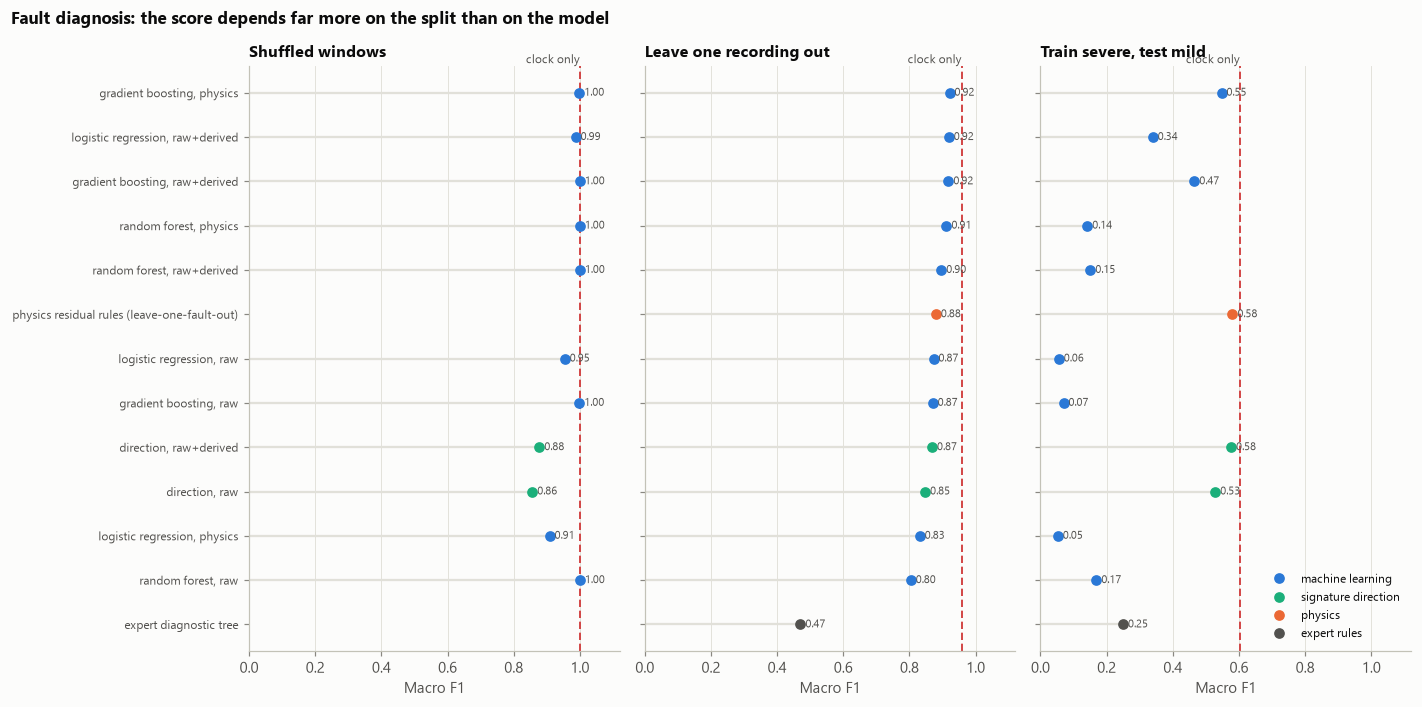

In [5]:
order = ["random", "loro", "incipient"]
plot_df = res.copy()
plot_df["label"] = plot_df["method"].str.replace(" | ", ", ", regex=False)
methods = (plot_df[plot_df["split"] == "loro"].sort_values("macro_f1")["label"].tolist())
fam_col = {"machine learning": pl.SERIES[0], "signature direction": pl.SERIES[2], "physics": pl.SERIES[1],
           "expert rules": pl.INK_2}
fig, axes = plt.subplots(1, 3, figsize=(13, 6.5), sharey=True)
for ax, split in zip(axes, order):
    d = plot_df[plot_df["split"] == split].set_index("label").reindex(methods)
    for i, (lab, row) in enumerate(d.iterrows()):
        if pd.isna(row["macro_f1"]):
            continue
        ax.plot([0, row["macro_f1"]], [i, i], color=pl.GRID, lw=1.5, zorder=1)
        ax.scatter(row["macro_f1"], i, color=fam_col[row["family"]], s=36, zorder=3)
        ax.text(row["macro_f1"] + 0.015, i, f"{row['macro_f1']:.2f}", va="center", fontsize=7.5, color=pl.INK_2)
    clock = probe[(probe["features"] == "clock only") & (probe["split"] == split)]["macro_f1"].iloc[0]
    ax.axvline(clock, color=pl.STATUS["critical"], lw=1.2, ls=(0, (4, 2)))
    ax.text(clock, len(methods) - 0.4, "clock only", color=pl.INK_2, fontsize=8, ha="right", va="bottom")
    ax.set_xlim(0, 1.12)
    ax.set_title({"random": "Shuffled windows", "loro": "Leave one recording out", "incipient": "Train severe, test mild"}[split])
    ax.set_xlabel("Macro F1")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(methods)), methods, fontsize=8)
from matplotlib.lines import Line2D
axes[2].legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=k) for k, c in fam_col.items()],
               loc="lower right", fontsize=8)
fig.suptitle("Fault diagnosis: the score depends far more on the split than on the model", x=0.01, ha="left",
             fontweight="bold", fontsize=11)
fig.tight_layout()
pl.save(fig, "04_diagnosis_scores")
plt.show()

**What the comparison shows**

1. **Shuffled splits are meaningless here**: tree models score 1.00 on every feature set, as does the
   clock.
2. **Leave one recording out**: the best models reach a macro F1 of about 0.92, and the physics
   rules, which never saw the scored fault, reach about the same. All still sit at or below the clock
   shortcut, so this split alone cannot show that the sensors are doing the work.
3. **Train on severe, test on mild**: most ML models collapse (macro F1 0.05-0.17 on raw features).
   They learned "far from healthy in direction X", and mild faults are close to healthy. Methods that
   use the **direction** of a deviation rather than its distance (the physics rules 0.58, the
   signature direction 0.53-0.58) hold up best, together with gradient boosting on the physics
   residuals (0.55). Even here the clock reaches 0.60, so only the physics rules' result is clean
   evidence: they reach it with no clock input and without having seen any recording of the fault.

## 3. Where the errors are

Confusion matrices for the best leave-one-recording-out ML model and the physics rules.

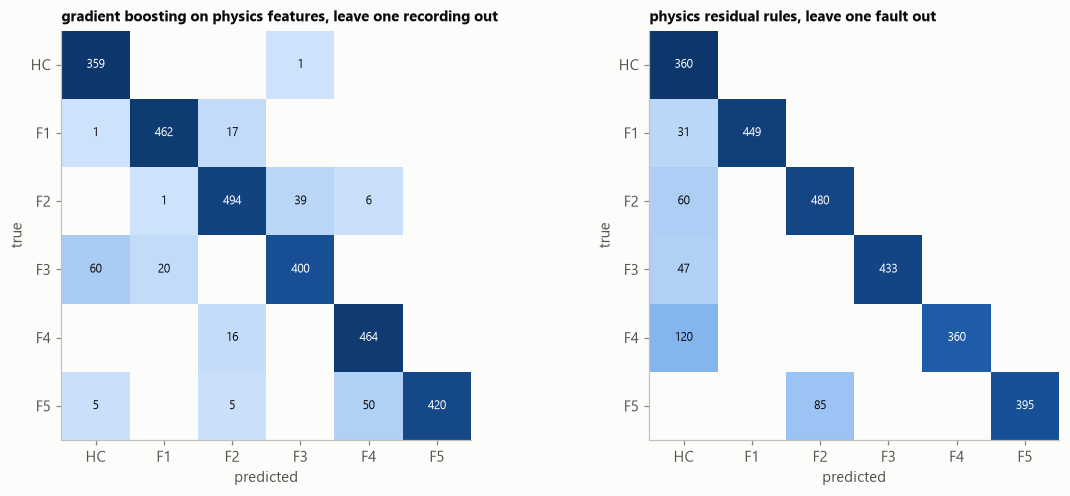

In [6]:
best = res[(res["split"] == "loro") & (res["family"] == "machine learning")].sort_values("macro_f1").iloc[-1]
mn, fs = best["method"].split(" | ")
p_best = preds[("loro", fs, mn)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (title, p) in zip(axes, [(f"{mn} on {fs} features, leave one recording out", p_best),
                                 ("physics residual rules, leave one fault out", phys_pred)]):
    labs = LABELS + (["unknown"] if (p == "unknown").any() else [])
    cm = confusion_matrix(y, p.astype(str), labels=labs)[: len(LABELS)]
    cmn = cm / cm.sum(axis=1, keepdims=True)
    cmap = pl.BLUE_RAMP.copy()
    cmap.set_bad(pl.SURFACE)
    ax.imshow(np.ma.masked_where(cm == 0, cmn), cmap=cmap, vmin=0, vmax=1)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                        color="white" if cmn[i, j] > 0.55 else pl.INK)
    ax.set_xticks(range(len(labs)), labs)
    ax.set_yticks(range(len(LABELS)), LABELS)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(title, fontsize=9.5)
    ax.grid(False)
fig.tight_layout()
pl.save(fig, "04_confusion")
plt.show()

Both approaches fail on the same few recordings, and they are the mildest settings. Per recording
(majority vote over its 60 windows):

In [7]:
per_run = pd.DataFrame({
    "condition": w.groupby("run_id", sort=False)["condition"].first(),
    "severity": w.groupby("run_id", sort=False)["severity"].first(),
    "physics rules": phys_pred.groupby(w["run_id"], sort=False).agg(lambda s: s.value_counts().index[0]),
    f"{mn} | {fs}": p_best.groupby(w["run_id"], sort=False).agg(lambda s: s.value_counts().index[0]),
    "expert tree": tree_pred.groupby(w["run_id"], sort=False).agg(lambda s: s.value_counts().index[0]),
})
wrong = per_run[(per_run["physics rules"] != per_run["condition"]) | (per_run[f"{mn} | {fs}"] != per_run["condition"])]
wrong

,condition,severity,physics rules,gradient boosting | physics,expert tree
run_id,,,,,
F1-010,F1,10.0,HC,F1,"detected, not isolated"
F2-020,F2,20.0,HC,F3,F1/F2/F4
F3-010,F3,10.0,HC,HC,F1/F2/F4
F4-020,F4,20.0,HC,F4,F1/F2/F4
F4-030,F4,30.0,HC,F4,F1/F2/F4
F5-010,F5,10.0,F2,F4,F1/F2/F4


* **F2 at 20 % and F4 at 20-30 %** are called healthy by the physics rules. Notebook 03 showed they
  produce no hydraulic change (the valves pass no flow yet), so "healthy" is the physically correct
  answer: these labels describe a valve command, not a fault. The gradient-boosting model labels the
  two leak settings "F4" anyway. It cannot be seeing a leak that is not there; it is matching the
  afternoon drift pattern shared with the neighbouring leak recordings, which is the time shortcut
  again.
* **The mildest blockage settings (F1 10 %, F3 10 %)** sit right at the detection limit.
* **F5 at 10 %** is the instructive one. The physics rules call it a pump fault: by 15:43 the pump
  was delivering about 3 % less than in the morning, the pump residual crossed its limit, and the
  nozzle residual had not yet. It is a false isolation caused by drift, exactly the failure the twin
  design must guard against (notebook 06).

How much do the physically empty settings change the headline numbers?

In [8]:
empty = w["run_id"].isin(["F2-020", "F4-020", "F4-030"])
sens = []
for name, p in [("physics residual rules", phys_pred), (f"{mn} | {fs} (loro)", p_best),
                ("expert tree", tree_pred)]:
    sens.append({"method": name, "macro F1, all windows": dg.score(y, p)["macro_f1"],
                 "macro F1, without the 3 empty settings": dg.score(y[~empty], p[~empty])["macro_f1"]})
pd.DataFrame(sens)

D:\files\fuel-system-digital-twin\.venv\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
D:\files\fuel-system-digital-twin\.venv\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,method,"macro F1, all windows","macro F1, without the 3 empty settings"
0,physics residual rules,0.880,0.940
1,gradient boosting | physics (loro),0.921,0.938
2,expert tree,0.471,0.474


## 4. How severe is it?

Once a fault is isolated, its size matters for maintenance planning. The physics residuals give a
physical severity directly (resistance ratio of a blocked section, or share of pump delivery lost).
The question here is how well that physical number tracks the emulated setting, and how precisely
the setting could be recovered from it.

In [9]:
sev_rows, sev_pts = [], []
for f in config.FAULTS:
    m = w["condition"] == f
    col = {"F1": "r_filter", "F2": "r_pump", "F3": "r_valve", "F4": "r_pump", "F5": "r_nozzle"}[f]
    phys = (1 + R.loc[m, col]) if f in ("F1", "F3", "F5") else R.loc[m, col]
    travel = w.loc[m, "severity"]
    rho = spearmanr(phys, travel).statistic
    # leave-one-recording-out: monotone map physical severity -> valve travel
    errs = []
    for run in w.loc[m, "run_id"].unique():
        tr = w.loc[m, "run_id"] != run
        iso = IsotonicRegression(out_of_bounds="clip").fit(phys[tr.to_numpy()], travel[tr.to_numpy()])
        pred = iso.predict(phys[~tr.to_numpy()])
        errs.append(np.abs(pred - travel[~tr.to_numpy()]).mean())
        sev_pts.append({"fault": f, "run_id": run, "travel": travel[~tr.to_numpy()].iloc[0], "predicted": pred.mean()})
    sev_rows.append({"fault": f, "physical severity": "resistance ratio" if f in ("F1", "F3", "F5") else "lost delivery",
                     "Spearman rho (windows)": rho,
                     "mean abs error, valve travel (pct points, leave one recording out)": np.mean(errs)})
sev_tab = pd.DataFrame(sev_rows)
sev_tab.to_csv(config.TABLE_DIR / "04_severity.csv", index=False)
sev_tab

,fault,physical severity,Spearman rho (windows),"mean abs error, valve travel (pct points, leave one recording out)"
0,F1,resistance ratio,0.992,4.494
1,F2,lost delivery,0.994,4.515
2,F3,resistance ratio,0.992,4.608
3,F4,lost delivery,0.970,6.363
4,F5,resistance ratio,0.992,4.625


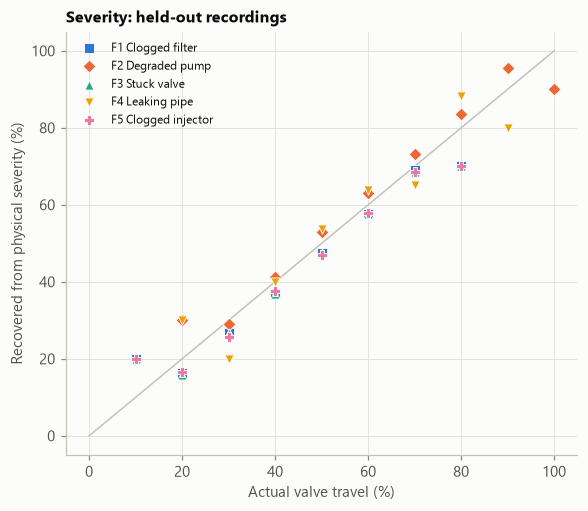

In [10]:
pts = pd.DataFrame(sev_pts)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 100], [0, 100], color=pl.AXIS, lw=1)
for f in config.FAULTS:
    d = pts[pts["fault"] == f]
    ax.scatter(d["travel"], d["predicted"], color=pl.CONDITION_COLORS[f], marker=pl.CONDITION_MARKERS[f], s=36,
               label=f"{f} {config.CONDITION_NAMES[f]}", edgecolor=pl.SURFACE, linewidth=0.6, zorder=3)
ax.set_xlabel("Actual valve travel (%)")
ax.set_ylabel("Recovered from physical severity (%)")
ax.set_title("Severity: held-out recordings")
ax.legend(fontsize=8)
pl.save(fig, "04_severity")
plt.show()

Physical severity rises monotonically with valve travel for every fault (rank correlation 0.97-0.99).
The setting of an unseen recording is recovered to within about 4.5 percentage points on average
(6.4 for the leak), and most of that error comes from the two ends of each sweep: when the mildest
or the most severe recording is held out, the mapping has to extrapolate and clips at the nearest
setting it knows. For the leak, the dead band below 30-35 % travel also makes 20 % and 30 % look
alike. For maintenance, the physical number (how much resistance, how much flow lost) is the more
useful output anyway.

## 5. Conclusions

* On this dataset, **accuracy figures are cheap and mostly uninformative**: a shuffled split gives
  100 %, and the clock alone gives 96 % with recordings held out and 0.60 macro F1 on mild faults.
  Because the label is tied to time on every split, the trustworthy evidence comes from a method that
  cannot use time and never saw the fault: the physics residual rules isolate every recording that
  has a physical effect except the mildest blockage settings and one drift-induced false isolation.
* Under the demanding test (learn from clear faults, recognise mild ones), methods built on the
  **direction** of deviation generalise; standard classifiers that learn distances from healthy do
  not.
* The remaining errors are at the physical detection limit (settings that change nothing or almost
  nothing) and one drift-induced false isolation. Fixing those needs more information (fluid
  temperature, a healthy reference recorded through the day), not a different classifier.
* Severity is best reported in physical units; it tracks the emulated setting monotonically.